In [49]:
# Librerias
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import folium
import branca
import numpy as np

# Exploracion del dataset de produccion no convencional

In [50]:
# Buscar un CSV local; si no está disponible, usar la fuente original online.
raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent
ruta_csv = raiz / 'data' / 'raw' / 'produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv'
print('CSV local disponible:', ruta_csv.is_file())

CSV local disponible: False


In [51]:
URL_CSV = 'https://github.com/molijoaquin-DA/vaca-muerta-produccion/raw/refs/heads/main/data/raw/produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv'
fuente = ruta_csv if ruta_csv.is_file() else URL_CSV
df = pd.read_csv(fuente, encoding='utf-8-sig', low_memory=False)
print('Fuente:', fuente)
print(f'Filas: {len(df):,} | Columnas: {df.shape[1]}')
display(df.head())

Fuente: https://github.com/molijoaquin-DA/vaca-muerta-produccion/raw/refs/heads/main/data/raw/produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv
Filas: 431,068 | Columnas: 40


,idempresa,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,iny_gas,iny_co2,...,cuenca,provincia,coordenadax,coordenaday,tipo_de_recurso,proyecto,clasificacion,subclasificacion,sub_tipo_recurso,fecha_data
0,YSUR,2018,1,133084,1.562,83.063,3.41,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-69.190117,-39.085986,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2018-01-31
1,YSUR,2015,1,136581,0.000,91.120,8.95,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-69.195470,-39.088767,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2015-01-31
2,YSUR,2018,1,154107,35.104,515.544,26.97,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-69.185172,-39.077997,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2018-01-31
3,YSUR,2017,1,156503,108.170,1315.590,10.30,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.810387,-39.024510,NO CONVENCIONAL,Sin Proyecto,EXPLOTACION,DESARROLLO,TIGHT,2017-01-31
4,YSUR,2018,1,131345,3.705,317.875,5.83,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.850549,-39.016005,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2018-01-31


|  # | Campo                    | Tipo      | Descripción                                                |
| -: | ------------------------ | --------- | ---------------------------------------------------------- |
|  0 | `idempresa`              | `str`     | Identificador de la empresa operadora del pozo.            |
|  1 | `anio`                   | `int64`   | Año informado.                                             |
|  2 | `mes`                    | `int64`   | Mes informado.                                             |
|  3 | `idpozo`                 | `int64`   | Identificador del pozo por formación productiva.           |
|  4 | `prod_pet`               | `float64` | Producción de petróleo (en m³).                            |
|  5 | `prod_gas`               | `float64` | Producción de gas (en miles de m³).                        |
|  6 | `prod_agua`              | `float64` | Producción de agua (en m³).                                |
|  7 | `iny_agua`               | `float64` | Inyección de agua (en m³).                                 |
|  8 | `iny_gas`                | `float64` | Inyección de gas (en miles de m³).                         |
|  9 | `iny_co2`                | `float64` | Inyección de CO₂ (en miles de m³).                         |
| 10 | `iny_otro`               | `float64` | Inyección de otros productos (en m³).                      |
| 11 | `tef`                    | `float64` | Tiempo efectivo de funcionamiento del pozo.                |
| 12 | `vida_util`              | `float64` | Vida útil estimada del pozo.                               |
| 13 | `tipoextraccion`         | `str`     | Tipo de extracción de los fluidos del pozo.                |
| 14 | `tipoestado`             | `str`     | Estado en el que se encuentra el pozo.                     |
| 15 | `tipopozo`               | `str`     | Característica de funcionamiento del pozo.                 |
| 16 | `observaciones`          | `str`     | Observaciones.                                             |
| 17 | `fechaingreso`           | `date-time`     | Fecha de carga de los datos.                               |
| 18 | `rectificado`            | `str`     | Indica si los datos fueron rectificados por el operador.   |
| 19 | `habilitado`             | `str`     | Indica si el registro está habilitado para su publicación. |
| 20 | `idusuario`              | `int64`   | Identificador del usuario de carga de los datos.           |
| 21 | `empresa`                | `str`     | Nombre de la empresa operadora.                            |
| 22 | `sigla`                  | `str`     | Identificador único de la boca del pozo.                   |
| 23 | `formprod`               | `str`     | Identificador de la formación productiva.                  |
| 24 | `profundidad`            | `float64` | Profundidad del pozo.                                      |
| 25 | `formacion`              | `str`     | Formación productiva.                                      |
| 26 | `idareapermisoconcesion` | `str`     | Identificador del área, permiso o concesión.               |
| 27 | `areapermisoconcesion`   | `str`     | Nombre del área, permiso o concesión.                      |
| 28 | `idareayacimiento`       | `str`     | Identificador del yacimiento.                              |
| 29 | `areayacimiento`         | `str`     | Nombre del yacimiento.                                     |
| 30 | `cuenca`                 | `str`     | Nombre de la cuenca sedimentaria.                          |
| 31 | `provincia`              | `str`     | Nombre de la provincia.                                    |
| 32 | `coordenadax`            | `float64` | Coordenada X del pozo.                                     |
| 33 | `coordenaday`            | `float64` | Coordenada Y del pozo.                                     |
| 34 | `tipo_de_recurso`        | `str`     | Tipo de recurso.                                           |
| 35 | `proyecto`               | `str`     | Nombre del proyecto asociado al pozo.                      |
| 36 | `clasificacion`          | `str`     | Clasificación del pozo.                                    |
| 37 | `subclasificacion`       | `str`     | Subclasificación del pozo.                                 |
| 38 | `sub_tipo_recurso`       | `str`     | Tipo de recurso hidrocarburífero.                          |
| 39 | `fecha_data`             | `date-time`     | Fecha asociada a los datos.                                |


**Campos que podemos descartar:**

| Campo | Razón |
|---|---|
| `fechaingreso` | Nos interesa la fecha de la data no la de ingreso de la data |

In [52]:
# Descarte de la columna fechaingreso
df.drop(columns=['fechaingreso'], inplace=True)

Veremos la relación entre "idpozo", "formprod" y "sigla". Según los campos, idpozo y formprod identifican a un pozo mientras que "sigla" identifica a la boca del pozo en forma de código único válido para Argentina.

Comprobemos:<br>
Una pregunta natural sería ver si hay algún idpozo que está en diferentes formprod (formaciones)

In [53]:
for col in ['idpozo', 'formprod', 'sigla']:
  print(f'Valores nulos del campo {col}:', df[col].isna().sum())

Valores nulos del campo idpozo: 0
Valores nulos del campo formprod: 0
Valores nulos del campo sigla: 0


In [54]:
pozos_varias_formaciones = (
    df.groupby('idpozo')['formprod']
      .nunique()
      .loc[lambda x: x > 1]
)

print('Cantidad de idpozos en diferente formación:')
print(len(pozos_varias_formaciones))

Cantidad de idpozos en diferente formación:
0


In [55]:
print('Número máximo de siglas correspondiente a un (idpozo, formprod):')
df.groupby(['idpozo', 'formprod'])['sigla'].nunique().max()

Número máximo de siglas correspondiente a un (idpozo, formprod):


1

La comprobación anterior verifica una sigla por combinación de identificadores. Comprobamos también la dirección inversa antes de afirmar una relación uno a uno. Estas relaciones describen el dataset observado.

In [56]:
relaciones = df[['idpozo', 'formprod', 'sigla']].drop_duplicates()
print('Máximo de pares idpozo/formprod por sigla:', relaciones.groupby('sigla').size().max())

# Filtrar y mostrar las siglas que tienen más de un par idpozo/formprod
siglas_duplicadas = relaciones.groupby('sigla').filter(lambda x: len(x) > 1)
display(siglas_duplicadas.sort_values(by='sigla'))

Máximo de pares idpozo/formprod por sigla: 3


,idpozo,formprod,sigla
96,133430,PREC,AEA.NQ.RCo.x-2001
370502,162701,LAJA,AEA.NQ.RCo.x-2001
57,134777,PREC,APA.Nq.Gu-1182(d)
366,157603,BASA,APA.Nq.Gu-1182(d)
73,137212,BASA,APA.Nq.Gu-1184(d)
...,...,...,...
8744,128998,QTUC,YPF.Nq.RN.xp-58
8300,159146,LMOL,YPF.RN.LCa.a-13
8250,159145,LAJA,YPF.RN.LCa.a-13
9709,156356,LMOL,YPF.RN.LCa.xp-10


Una sigla puede corresponder a varios idpozo, esto se da porque una boca de pozo puede utilizarse para diferentes formaciones y por lo cual (por cómo se crea el dataset) se identifican con diferentes idpozo.

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 431068 entries, 0 to 431067
Data columns (total 39 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   idempresa               431068 non-null  object 
 1   anio                    431068 non-null  int64  
 2   mes                     431068 non-null  int64  
 3   idpozo                  431068 non-null  int64  
 4   prod_pet                431068 non-null  float64
 5   prod_gas                431068 non-null  float64
 6   prod_agua               431068 non-null  float64
 7   iny_agua                431068 non-null  float64
 8   iny_gas                 431068 non-null  float64
 9   iny_co2                 431068 non-null  float64
 10  iny_otro                431068 non-null  float64
 11  tef                     431068 non-null  float64
 12  vida_util               9165 non-null    float64
 13  tipoextraccion          430447 non-null  object 
 14  tipoestado          

La columna "fecha_data" se deberá cambiar a tipo date-time. El resto de columnas están bien seteadas

In [58]:
print("¿Todos los registros de fecha son YYYY-MM-DD o YYYY-DD-MM?")
print(df['fecha_data'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all())

print('¿Algún valor es YYYY-DD-MM?')
print(pd.to_datetime(df['fecha_data'], format='%Y-%d-%m', errors='coerce').notna().any())

¿Todos los registros de fecha son YYYY-MM-DD o YYYY-DD-MM?
True
¿Algún valor es YYYY-DD-MM?
False


Por lo que la columna fecha_data tiene formato YYYY-MM-DD

In [59]:
# Seteo del tipo de dato para la columna fecha_data
df['fecha_data'] = pd.to_datetime(df['fecha_data'], format='%Y-%m-%d')

In [60]:
print('¿La columna anio coincide con fecha_data?')
print((df['anio'] == df['fecha_data'].dt.year).all())

print('¿La columna mes coincide con fecha_data?')
print((df['mes'] == df['fecha_data'].dt.month).all())

¿La columna anio coincide con fecha_data?
True
¿La columna mes coincide con fecha_data?
True


In [61]:
#Identificando el periodo disponible
print("Primer mes:", df['fecha_data'].min())
print("Ultimo mes:", df['fecha_data'].max())
print("Registros con fecha invalida:", df['fecha_data'].isna().sum())
print("Identificadores pozo-formacion:", df["idpozo"].nunique())

Primer mes: 2006-01-31 00:00:00
Ultimo mes: 2026-09-30 00:00:00
Registros con fecha invalida: 0
Identificadores pozo-formacion: 5164


Como los registros represetan los datos de todo el mes entonces nos quedaremos sólo con las columnas anio y mes y desecharemos la columna de fecha_data

In [62]:
# Eliminación de la columna fecha_data
df.drop(columns=['fecha_data'], inplace=True)

In [63]:
# Explorar que contiene el dataframe

for columna in ["empresa", "formacion", "tipopozo"]:
    print(f"\nRegistros por {columna}:")
    display(
        df[columna]
        .value_counts(dropna=False)
        .rename_axis(columna)
        .reset_index(name="registros")
    )


Registros por empresa:


,empresa,registros
0,YPF S.A.,233513
1,CAPEX S.A.,21590
2,PLUSPETROL S.A.,20998
3,PAN AMERICAN ENERGY SL,20784
4,COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,16327
5,TECPETROL S.A.,16117
6,TOTAL AUSTRAL S.A.,16000
7,PAMPA ENERGIA S.A.,13918
8,SHELL ARGENTINA S.A.,9439
9,VISTA ENERGY ARGENTINA SAU,8680



Registros por formacion:


,formacion,registros
0,vaca muerta,223323
1,lajas,78391
2,mulichinco,35267
3,los molles,28442
4,magallanes,16007
5,precuyo,14717
6,quintuco,11116
7,punta rosada,9805
8,agrio,5823
9,basamento,2203



Registros por tipopozo:


,tipopozo,registros
0,Gasífero,232330
1,Petrolífero,168337
2,Otro tipo,28911
3,Sumidero,759
4,NaN,621
5,Inyección de Agua,56
6,Inyección de Gas,52
7,Acuífero,2


## Inicio de selección de campos a utilizar para el análisis exploratorio y predictivo.

Nos quedamos con la empresa ypf que es la que más registros posee

In [64]:
df_ypf = df[df['idempresa'] == 'YPF'].copy()
df_ypf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 233513 entries, 7721 to 241233
Data columns (total 38 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   idempresa               233513 non-null  object 
 1   anio                    233513 non-null  int64  
 2   mes                     233513 non-null  int64  
 3   idpozo                  233513 non-null  int64  
 4   prod_pet                233513 non-null  float64
 5   prod_gas                233513 non-null  float64
 6   prod_agua               233513 non-null  float64
 7   iny_agua                233513 non-null  float64
 8   iny_gas                 233513 non-null  float64
 9   iny_co2                 233513 non-null  float64
 10  iny_otro                233513 non-null  float64
 11  tef                     233513 non-null  float64
 12  vida_util               393 non-null     float64
 13  tipoextraccion          233508 non-null  object 
 14  tipoestado            

Nuestra áreas propuestas de interes fueron seleccionadas por sus diferentes distribuciones de fluidos en la formación Vaca Muerta:
*   Loma Campana (mayormente petróleo volatil)
*   La Amarga Chica (petróleo negro)
*   El Orejano (gas seco)

In [65]:
df_areas = df_ypf[df_ypf['areayacimiento'].isin(['LOMA CAMPANA', 'LA AMARGA CHICA', 'EL OREJANO'])].copy()
df_areas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47759 entries, 7722 to 241223
Data columns (total 38 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idempresa               47759 non-null  object 
 1   anio                    47759 non-null  int64  
 2   mes                     47759 non-null  int64  
 3   idpozo                  47759 non-null  int64  
 4   prod_pet                47759 non-null  float64
 5   prod_gas                47759 non-null  float64
 6   prod_agua               47759 non-null  float64
 7   iny_agua                47759 non-null  float64
 8   iny_gas                 47759 non-null  float64
 9   iny_co2                 47759 non-null  float64
 10  iny_otro                47759 non-null  float64
 11  tef                     47759 non-null  float64
 12  vida_util               7 non-null      float64
 13  tipoextraccion          47759 non-null  object 
 14  tipoestado              47759 non-null 

En el dataset ypf de por sí reporta pocos datos en la columna vida_util y observaciones. El resto de datos no presentan valores nulos.

In [66]:
categoricas = df_areas.select_dtypes(include=['object']).columns

for col in categoricas:
    print(f'\n{"=" * 60}')
    print(f'{col} ({df_areas[col].nunique()} valores únicos)')
    print('=' * 60)
    print(df_areas[col].value_counts(dropna=False))


idempresa (1 valores únicos)
idempresa
YPF    47759
Name: count, dtype: int64

tipoextraccion (8 valores únicos)
tipoextraccion
Surgencia Natural            27385
Bombeo Mecánico              17604
Plunger Lift                  1723
Sin Sistema de Extracción      849
Electrosumergible               91
Bombeo Hidráulico               72
Gas Lift                        22
Jet Pump                        13
Name: count, dtype: int64

tipoestado (13 valores únicos)
tipoestado
Extracción Efectiva                   36122
Parado Transitoriamente                4770
En Estudio                             2851
En Espera de Reparación                1485
A Abandonar                            1101
Abandonado                              558
En Inyección Efectiva                   323
Otras Situación Inactivo                215
En Reserva de Gas                       182
Abandono Temporario                      81
Parado Alta Relación Agua/Petróleo       61
En Reparación                         

La columna de observaciones no aporta información relevante.

Algunas columnas poseen sólo un valor único por el filtrado de área y empresa que se hizo por lo que no aportarán al análisis y posteriores modelos de machine learning.

Dichas columnas son idempresa, habilitado, empresa, cuenca, provincia, tipo_de_recurso, proyecto y sub_tipo_recurso.

En definitiva, el datasete "df_areas" posee información de la empresa ypf, sobre la cuenca neuquina, en la provincia de Neuquén, sin proyecto asociado y el tipo de recurso hidrocarburífero es el Shale (recurso no convencional)

Recurso no convencional: normalmente requiere técnicas como fractura hidráulica y, en muchos casos, perforación horizontal.

In [67]:
# Las columnas formprod y formacion refieren a lo mismo, por las dudas se chequea:
df_areas[['formprod', 'formacion']].value_counts()

,,count
formprod,formacion,
VMUT,vaca muerta,47475
CENT,centenario,280
QTUC,quintuco,4


Efectivamente, es redundate tener ambas columnas.

In [68]:
# Lo mismo pasa con idareapermisoconcesion, areapermisoconcesion y areayacimiento
df_areas[['idareayacimiento', 'idareapermisoconcesion', 'areapermisoconcesion', 'areayacimiento']].value_counts()

,,,,count
idareayacimiento,idareapermisoconcesion,areapermisoconcesion,areayacimiento,
LCAM,LCAM,LOMA CAMPANA,LOMA CAMPANA,21399
LAC,LAC,LA AMARGA CHICA,LA AMARGA CHICA,15710
ELOR,ELOR,EL OREJANO,EL OREJANO,10650


In [69]:
numericas = df_areas.select_dtypes(include=['int64', 'float64']).columns

for col in numericas:
    print(f'\n{"=" * 60}')
    print(f'{col} ({df_areas[col].nunique()} valores únicos)')
    print('=' * 60)
    print(df_areas[col].value_counts(dropna=False))


anio (19 valores únicos)
anio
2025    6856
2024    6047
2026    5602
2023    5314
2022    4553
2021    3823
2020    3430
2019    3150
2018    2760
2017    2349
2016    1739
2015    1052
2014     740
2013     119
2006      60
2007      60
2012      46
2008      45
2011      14
Name: count, dtype: int64

mes (12 valores únicos)
mes
9     4278
8     4214
7     4159
6     4119
5     4061
4     4009
3     3972
2     3900
1     3848
12    3783
11    3740
10    3676
Name: count, dtype: int64

idpozo (640 valores únicos)
idpozo
135484    220
137008    209
145551    189
145552    189
145550    189
         ... 
167577      1
167578      1
167581      1
167580      1
167579      1
Name: count, Length: 640, dtype: int64

prod_pet (28546 valores únicos)
prod_pet
0.00      15965
1.06         11
7.56          9
11.20         8
12.16         8
          ...  
654.06        1
435.01        1
621.72        1
474.50        1
637.51        1
Name: count, Length: 28546, dtype: int64

prod_gas (22768 valo

Para las columnas numéricas el rango de años cubre 2006-2008 y 2011-2025, en esta última se nota un claro aumento de los datos año tras año.

Se cubren todos los meses, la inyección de agua sólo sucede en 322 datos, no hay inyección de gas, co2, ni de otro tipo.

Hay un usuario que cargó todos los datos de este dataframe.

La columna de vida_util detalla algunos datos con valor 0, habría que investigar a qué se deben

In [70]:
# Se procede a eliminar columnas sin valor adicional
df_areas.drop(columns =['idusuario', 'observaciones', 'idempresa', 'habilitado',
                        'empresa', 'cuenca', 'provincia', 'tipo_de_recurso',
                        'proyecto', 'sub_tipo_recurso'], inplace=True)

# Se eliminan las columnas redundantes
df_areas.drop(columns=['formprod', 'idareayacimiento', 'idareapermisoconcesion', 'areapermisoconcesion'], inplace=True)

# Como no hay inyección de gas, co2 ni de otro tipo se eliminan dichas columnas
df_areas.drop(columns=['iny_gas', 'iny_co2', 'iny_otro'], inplace=True)

In [71]:
# Investigación de los ceros en vida_util
df_areas[df_areas['vida_util']==0][['idpozo', 'formacion', 'tipoestado']]

,idpozo,formacion,tipoestado
61125,157858,vaca muerta,A Abandonar
81252,157858,vaca muerta,A Abandonar
95053,157858,vaca muerta,A Abandonar
109633,157858,vaca muerta,A Abandonar
133543,157858,vaca muerta,A Abandonar
146307,157858,vaca muerta,A Abandonar
164960,157858,vaca muerta,A Abandonar


Es sobre un mismo pozo que está en estado para abandondar así que el 0 es un valor válido

In [72]:
abandono_sin_vida = df_areas.loc[
    df_areas['tipoestado'].eq('A Abandonar') & df_areas['vida_util'].isna()
]
print('Registros A Abandonar sin vida_util:', len(abandono_sin_vida))
print('Pozos distintos en esos registros:', abandono_sin_vida['idpozo'].nunique())

Registros A Abandonar sin vida_util: 1094
Pozos distintos en esos registros: 50


Hay 1094 pozos con estado a abandonar pero que no se les setea vida_util = 0 por lo que dicha columna no aporta mucha información

Limpiamos esta columna ya que no nos aporta data util y no cargan con precision la vida util de cada idpozo/formacion

In [73]:
df_areas.drop(columns=['vida_util'], inplace=True)

## Inspección de pozos que inyectaron agua

Veamos los meses que se inyectó agua

In [74]:
print('Años disponibles:', sorted(df_areas['anio'].unique()))
print('Registros con inyección de agua positiva:', df_areas['iny_agua'].gt(0).sum())
print('Pozos con inyección de agua positiva:', df_areas.loc[df_areas['iny_agua'].gt(0), 'idpozo'].nunique())
print('Registros con profundidad cero (revisar):', df_areas['profundidad'].eq(0).sum())

Años disponibles: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Registros con inyección de agua positiva: 322
Pozos con inyección de agua positiva: 8
Registros con profundidad cero (revisar): 837


In [75]:
pozos_iny_agua = df_areas.loc[
    df_areas['iny_agua'] > 0,
    [
        'idpozo',
        'anio',
        'mes',
        'formacion',
        'iny_agua',
        'prod_pet',
        'prod_gas',
        'prod_agua',
        'tipoextraccion',
        'tipoestado',
        'tipopozo'
    ]
]
display(pozos_iny_agua.head())

,idpozo,anio,mes,formacion,iny_agua,prod_pet,prod_gas,prod_agua,tipoextraccion,tipoestado,tipopozo
8432,161956,2021,1,centenario,11321.17,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero
9829,161956,2024,1,centenario,30846.65,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero
12055,162479,2024,1,centenario,43590.01,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Inyección de Agua
12795,164032,2024,1,vaca muerta,28156.05,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero
13863,161956,2023,1,centenario,28586.77,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero


In [76]:
pozos_iny_agua.value_counts()

idpozo  anio  mes  formacion   iny_agua  prod_pet  prod_gas  prod_agua  tipoextraccion             tipoestado             tipopozo
166682  2026  9    centenario  29717.71  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
161956  2020  11   centenario  4212.30   0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
166318  2026  8    centenario  40131.46  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
              7    centenario  37443.25  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
              6    centenario  39775.47  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
                                                                                                                                     ..
161956  2021  5    centenario  8794.83   0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
              4    centenario  11678.59  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
              3    centenario  14063.70  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
              2    centenario  11925.91  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
              1    centenario  11321.17  0.0       0.0       0.0        Sin Sistema de Extracción  En Inyección Efectiva  Sumidero    1
Name: count, Length: 322, dtype: int64

In [77]:
pozos_iny_agua['tipoextraccion'].value_counts(dropna=False)

,count
tipoextraccion,
Sin Sistema de Extracción,322


En esos meses sólo inyectaron agua, sin extraer nada, y los tipos de pozos son sumidero e inyección de agua.

**Pozo de Inyección de Agua:**<br>
Perforación profunda para introducir agua, salmuera o fluidos industriales en formaciones geológicas confinadas con el fin de restaurar la presión perdida y empujar el crudo remanente hacia los pozos de producción.

**Pozo Sumidero:**<br>
Perforación profunda utilizada como el depósito final y definitivo para desechar los fluidos residuales altamente contaminantes que se generan durante la extracción de hidrocarburos.

## Datos duplicados

In [78]:
print('Cantidad de filas duplicadas:', df_areas.duplicated().sum())

print('Cantidad de filas duplicadas considerando columna mes, anio e idpozo:', df_areas[['anio', 'mes', 'idpozo']].duplicated().sum())

Cantidad de filas duplicadas: 0
Cantidad de filas duplicadas considerando columna mes, anio e idpozo: 0


## Filtrado del dataset

Se decidió poder avanzar con ciertas categorias exploratorias de los 3 yacimientos previamente filtrados. Dichas serán seleccionadas por la cantidad de datos que tengamos

In [79]:
df_areas[['formacion', 'areayacimiento', 'tipopozo','tipoextraccion']].value_counts()

formacion    areayacimiento   tipopozo           tipoextraccion           
vaca muerta  LOMA CAMPANA     Petrolífero        Bombeo Mecánico              12399
             LA AMARGA CHICA  Petrolífero        Surgencia Natural            10341
             LOMA CAMPANA     Petrolífero        Surgencia Natural             6241
             EL OREJANO       Gasífero           Surgencia Natural             5770
             LA AMARGA CHICA  Petrolífero        Bombeo Mecánico               4487
             EL OREJANO       Otro tipo          Surgencia Natural             4343
             LOMA CAMPANA     Petrolífero        Plunger Lift                  1279
                              Otro tipo          Bombeo Mecánico                607
                                                 Surgencia Natural              554
             EL OREJANO       Otro tipo          Sin Sistema de Extracción      323
             LA AMARGA CHICA  Petrolífero        Plunger Lift                   311
centenario   LA AMARGA CHICA  Sumidero           Sin Sistema de Extracción      238
vaca muerta  LOMA CAMPANA     Otro tipo          Sin Sistema de Extracción      201
             EL OREJANO       Gasífero           Plunger Lift                   132
             LA AMARGA CHICA  Otro tipo          Bombeo Mecánico                111
             LOMA CAMPANA     Petrolífero        Bombeo Hidráulico               72
             LA AMARGA CHICA  Otro tipo          Surgencia Natural               70
                              Petrolífero        Electrosumergible               69
             EL OREJANO       Petrolífero        Surgencia Natural               61
             LOMA CAMPANA     Sumidero           Sin Sistema de Extracción       44
centenario   LA AMARGA CHICA  Inyección de Agua  Sin Sistema de Extracción       42
vaca muerta  LA AMARGA CHICA  Petrolífero        Gas Lift                        22
             EL OREJANO       Otro tipo          Electrosumergible               21
             LA AMARGA CHICA  Petrolífero        Jet Pump                        13
quintuco     LA AMARGA CHICA  Petrolífero        Surgencia Natural                4
vaca muerta  LA AMARGA CHICA  Otro tipo          Plunger Lift                     1
                              Petrolífero        Sin Sistema de Extracción        1
             LOMA CAMPANA     Gasífero           Surgencia Natural                1
                              Petrolífero        Electrosumergible                1
Name: count, dtype: int64

Los pozos pasan por varios tipos de extracción a lo largo de su vida útil, veamos cuáles

In [80]:
# Obtener el conjunto de tipos de extracción únicos por pozo
pozos_comb = (
    df_areas.groupby('idpozo')['tipoextraccion']
    .agg(lambda x: tuple(sorted(set(x.dropna()))))
)

# Contar la cantidad de pozos por cada combinación de tipos de extracción
conteo_combinaciones = pozos_comb.value_counts().reset_index()
conteo_combinaciones.columns = ['Combinacion_Tipos', 'Cantidad_Pozos']

# Mostrar el resultado ordenado por la cantidad de pozos de mayor a menor
display(conteo_combinaciones)

,Combinacion_Tipos,Cantidad_Pozos
0,"(Bombeo Mecánico, Surgencia Natural)",286
1,"(Surgencia Natural,)",227
2,"(Bombeo Mecánico, Plunger Lift, Surgencia Natu...",36
3,"(Bombeo Mecánico, Plunger Lift, Sin Sistema de...",20
4,"(Sin Sistema de Extracción, Surgencia Natural)",19
5,"(Plunger Lift, Sin Sistema de Extracción, Surg...",12
6,"(Sin Sistema de Extracción,)",11
7,"(Electrosumergible, Surgencia Natural)",7
8,"(Plunger Lift, Surgencia Natural)",7
9,"(Gas Lift, Surgencia Natural)",6


La mayoría de datos viene dado por vaca muerta, las tres areas que abarcamos, los tipos de pozos petrolíferos y gasíferos y el tipo de extracción bombeo mecánico y surgencia natural.

Considerando todo esto decidimos filtrar más el dataset con las primeras filas del anterior df. Teniendo dos combinaciones, Bombeo Mecánico/Surgencia Natural (fila 0 de la tabla anterior) y Surgencia Natural (fila 1 de la tabla anterior).

In [81]:
# Combinaciones permitidas (filas 0 y 1 de la tabla)
combinaciones_permitidas = [
    ('Bombeo Mecánico', 'Surgencia Natural'),
    ('Surgencia Natural',)
]

# Identificar los pozos que cumplen
pozos_validos = pozos_comb[
    pozos_comb.isin(combinaciones_permitidas)
].index

# Conservar sus registros y aplicar los otros filtros
df_filtrado = df_areas[
    df_areas['idpozo'].isin(pozos_validos)
    & (df_areas['formacion'] == 'vaca muerta')
    & df_areas['tipopozo'].isin(['Petrolífero', 'Gasífero'])
].copy()

# Como nos quedamos con una sóla formación ahora la columna sigla ya es redundate
df_filtrado.drop(columns=['formacion', 'rectificado', 'sigla'], inplace=True)

print('Pozos con combinaciones permitidas:', len(pozos_validos))
print('Pozos tras los filtros restantes:', df_filtrado['idpozo'].nunique())

Pozos con combinaciones permitidas: 513
Pozos tras los filtros restantes: 512


In [82]:
# Localizacion de los pozos luego del filtrado

df_pozos_ubicacion = (
    df_filtrado[['idpozo', 'areayacimiento', 'coordenadax', 'coordenaday']]
    .drop_duplicates()
)

# Colores únicos para cada área/yacimiento
areas = df_pozos_ubicacion['areayacimiento'].unique()

colormap = branca.colormap.linear.Set1_09.scale(0, len(areas) - 1)

colores = {
    area: colormap(i)
    for i, area in enumerate(areas)
}

m = folium.Map(
    location=[
        df_pozos_ubicacion['coordenaday'].mean(),
        df_pozos_ubicacion['coordenadax'].mean()
    ],
    zoom_start=10,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri'
)

for _, row in df_pozos_ubicacion.dropna(
    subset=['coordenadax', 'coordenaday']
).iterrows():

    color = colores.get(row['areayacimiento'], 'gray')

    folium.CircleMarker(
        location=[row['coordenaday'], row['coordenadax']],
        radius=3,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8,
        popup=f"Pozo: {row['idpozo']}<br>"
              f"Área/Yacimiento: {row['areayacimiento']}"
    ).add_to(m)

m

## Creación de columnas

Las extracciones de petróleo, gas y agua dependen del tef (tiempo efectivo de extracción) por lo cual para el análisis es interesante ver cuál es la producción de dichos recursos por día efectivo

Por lo que se considera columnas nuevas, haciendo por ejemplo prod_pet / tef

In [83]:
# Para no dividir por cero se tiene que hacer esto
df_filtrado['prod_pet_dia'] = np.where(
    df_filtrado['tef'] != 0,
    df_filtrado['prod_pet'] / df_filtrado['tef'],
    df_filtrado['prod_pet']
)

df_filtrado['prod_gas_dia'] = np.where(
    df_filtrado['tef'] != 0,
    df_filtrado['prod_gas'] / df_filtrado['tef'],
    df_filtrado['prod_gas']
)

df_filtrado['prod_agua_dia'] = np.where(
    df_filtrado['tef'] != 0,
    df_filtrado['prod_agua'] / df_filtrado['tef'],
    df_filtrado['prod_agua']
)

In [84]:
df_filtrado[df_filtrado['tipoestado'] != "Extracción Efectiva"][["prod_pet_dia", "prod_gas_dia", "prod_agua_dia"]].describe()

,prod_pet_dia,prod_gas_dia,prod_agua_dia
count,2996.0,2996.0,2996.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


Sin el tipo de estado "extracción efectiva" no hay valores para ninguna extracción

In [85]:
# Mostrar las producciones calculadas por registro
columnas_mostrar = [
    'idpozo',
    'anio',
    'mes',
    'tef',
    'prod_pet_dia',
    'prod_gas_dia',
    'prod_agua_dia'
]

display(df_filtrado[columnas_mostrar].head(20))

,idpozo,anio,mes,tef,prod_pet_dia,prod_gas_dia,prod_agua_dia
7724,161685,2021,1,31.00,126.587419,19.953548,30.159677
7738,158425,2018,1,28.56,0.000000,249.716737,49.162465
7739,157108,2021,1,0.00,0.000000,0.000000,0.000000
7762,156710,2018,1,31.00,48.670323,6.732258,3.601290
7780,156469,2018,1,30.00,0.698667,6.000667,0.000000
7784,161423,2021,1,30.92,46.369340,5.175291,4.276197
7786,156475,2018,1,30.96,27.768734,4.181525,1.575904
7801,145882,2024,1,0.00,0.000000,0.000000,0.000000
7805,161512,2021,1,24.50,68.453061,6.820408,6.040816
7809,158752,2019,1,29.96,0.000000,357.620828,11.512016


In [86]:
df_filtrado.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
anio,30325.0,NaN,NaN,NaN,2022.165243,3.096953,2013.0,2020.0,2023.0,2025.0,2026.0
mes,30325.0,NaN,NaN,NaN,6.480363,3.393272,1.0,4.0,7.0,9.0,12.0
idpozo,30325.0,NaN,NaN,NaN,158930.140247,5314.650735,145735.0,156339.0,159500.0,163067.0,167581.0
prod_pet,30325.0,NaN,NaN,NaN,937.29746,1357.722654,0.0,40.52,435.34,1229.36,12288.66
prod_gas,30325.0,NaN,NaN,NaN,387.870915,1072.653706,0.0,27.43,92.48,245.25,13636.74
prod_agua,30325.0,NaN,NaN,NaN,342.970252,755.17554,0.0,2.22,56.8,300.02,15232.49
iny_agua,30325.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
tef,30325.0,NaN,NaN,NaN,24.371067,10.228961,0.0,23.71,29.71,30.71,31.0
tipoextraccion,30325,2,Surgencia Natural,18461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipoestado,30325,4,Extracción Efectiva,27329,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Una variable interesante a tener en cuenta es la edad del pozo, vamos a estimarla:

In [87]:
df_filtrado['fecha'] = pd.to_datetime({
    'year': df_filtrado['anio'],
    'month': df_filtrado['mes'],
    'day': 1
})

df_filtrado['fecha_inicio_estimada'] = (
    df_filtrado.loc[df_filtrado['tipoestado'] == "Extracción Efectiva"]
      .groupby('idpozo')['fecha']
      .transform('min')
)

# Se crea la edad pozo en meses, si no hubo actividad productiva se le pone edad de pozo 0
df_filtrado['edad_pozo_meses'] = np.where(
    df_filtrado['fecha_inicio_estimada'].notna(),
    (df_filtrado['fecha'].dt.year - df_filtrado['fecha_inicio_estimada'].dt.year) * 12
    + (df_filtrado['fecha'].dt.month - df_filtrado['fecha_inicio_estimada'].dt.month),
    0
)

df_filtrado.drop(columns=['fecha', 'fecha_inicio_estimada'], inplace=True)
df_filtrado[['idpozo', 'edad_pozo_meses']].head()

,idpozo,edad_pozo_meses
7724,161685,11.0
7738,158425,4.0
7739,157108,0.0
7762,156710,20.0
7780,156469,22.0


**Análsis con gráficos**




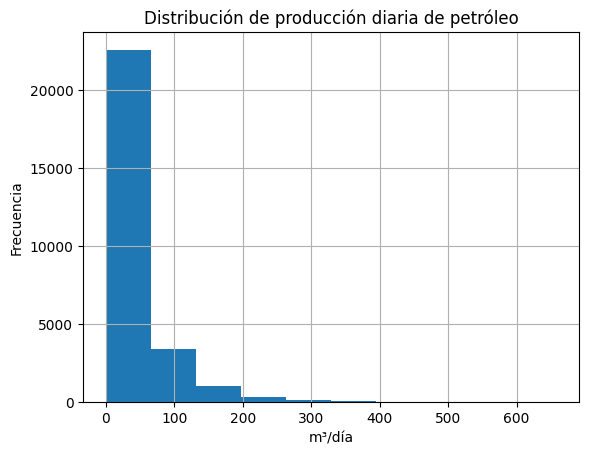

In [88]:
df_filtrado[df_filtrado['tipoestado'] == 'Extracción Efectiva']['prod_pet_dia'].hist()
plt.title('Distribución de producción diaria de petróleo')
plt.xlabel('m³/día')
plt.ylabel('Frecuencia')
plt.show()

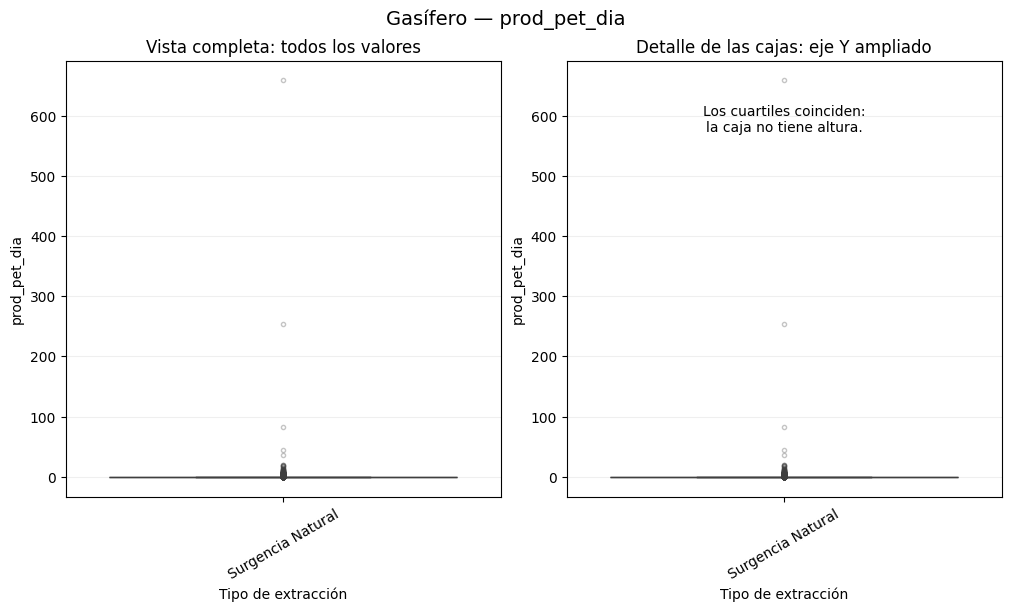

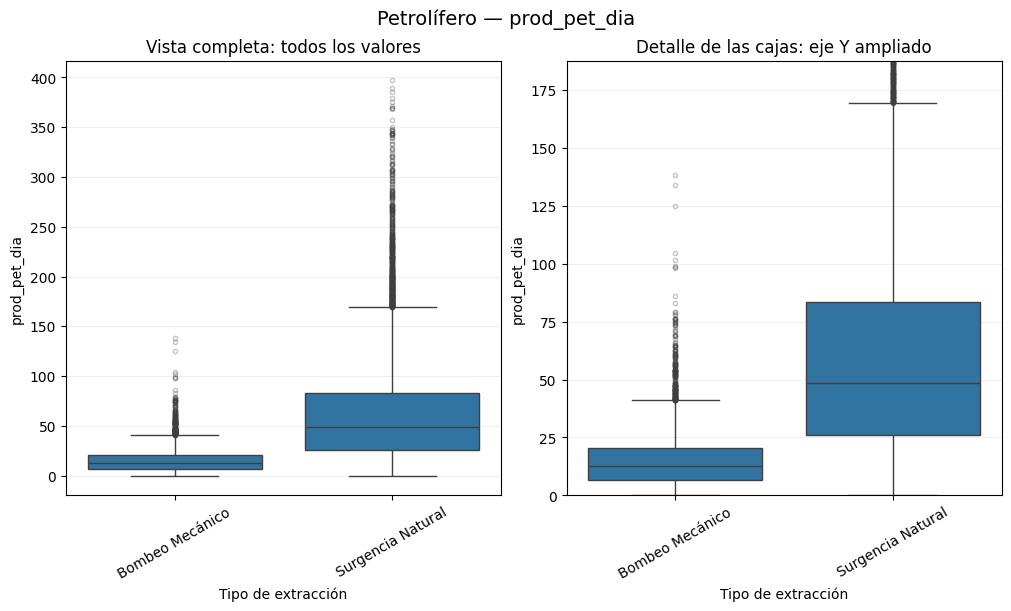

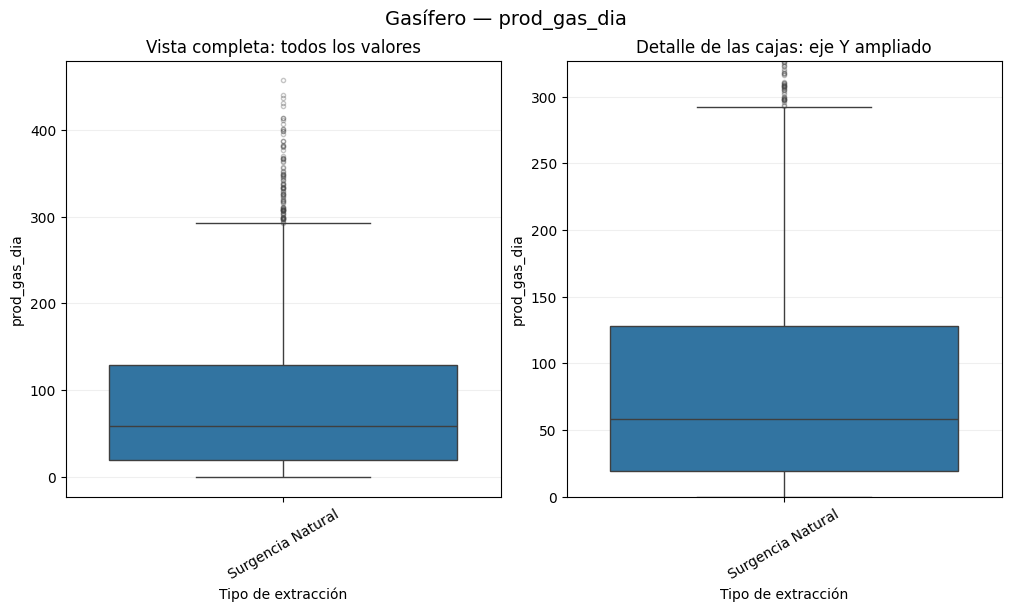

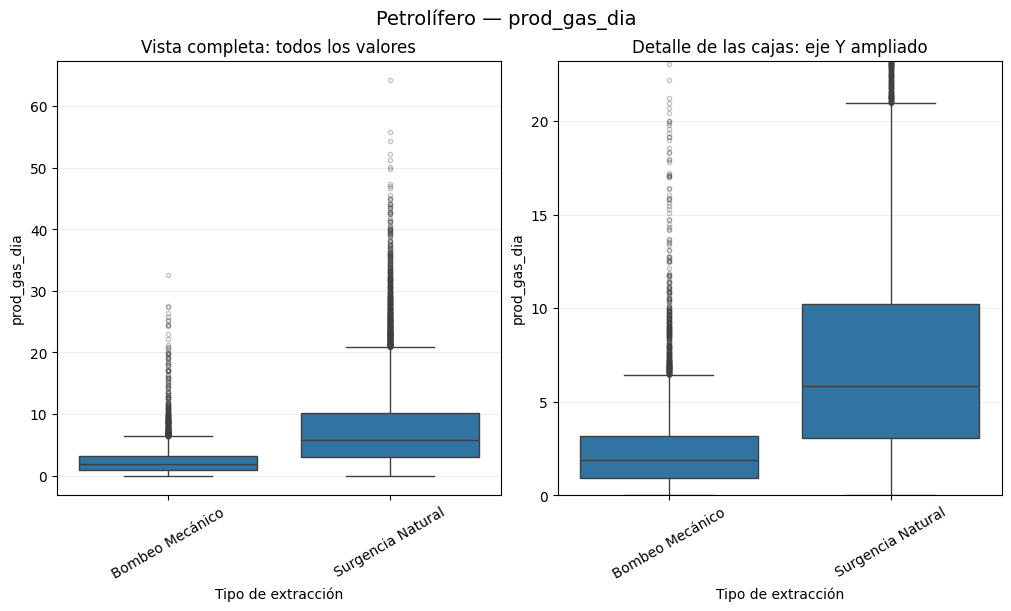

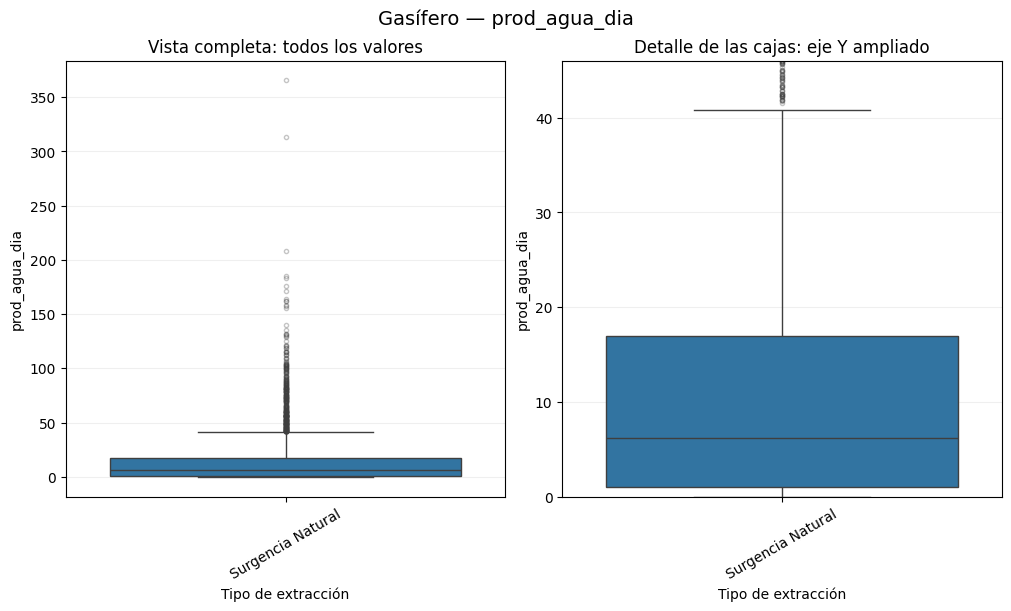

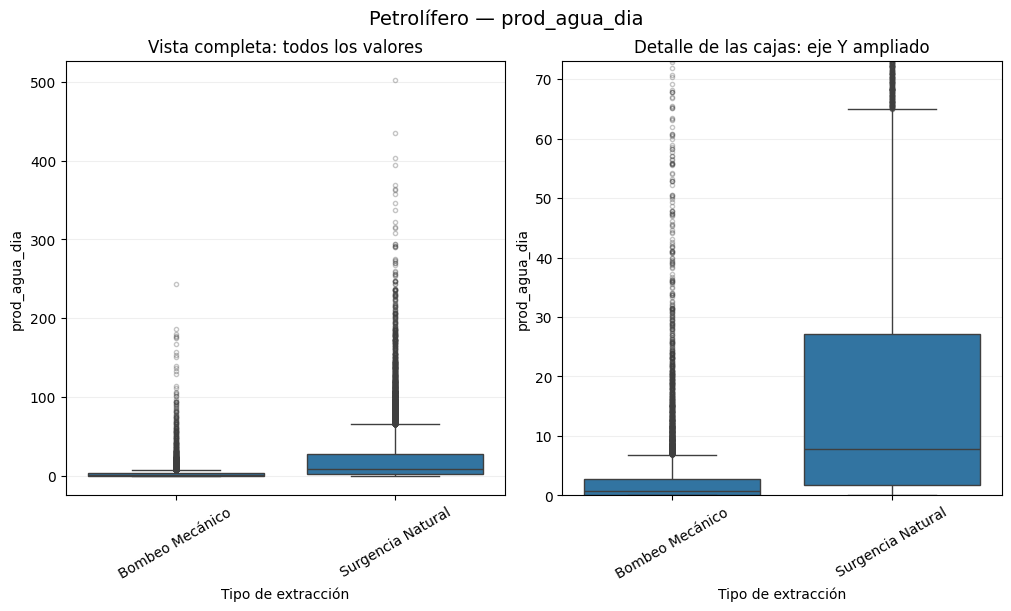

In [89]:
df_plot = df_filtrado.loc[
    df_filtrado['tipoestado'] == 'Extracción Efectiva'
].copy()

cols = ['prod_pet_dia', 'prod_gas_dia', 'prod_agua_dia']

for col in cols:
    for tipo, datos in df_plot.groupby('tipopozo'):
        datos = datos.dropna(subset=[col, 'tipoextraccion'])

        if datos.empty:
            continue

        orden = sorted(datos['tipoextraccion'].unique())

        fig, axes = plt.subplots(
            1, 2,
            figsize=(10, 6),
            constrained_layout=True
        )

        for ax in axes:
            sns.boxplot(
                data=datos,
                x='tipoextraccion',
                y=col,
                order=orden,
                showfliers=True,
                flierprops={
                    'marker': 'o',
                    'markersize': 3,
                    'alpha': 0.3
                },
                ax=ax
            )

            ax.set_xlabel('Tipo de extracción')
            ax.set_ylabel(col)
            ax.tick_params(axis='x', rotation=30)
            ax.grid(axis='y', alpha=0.2)

        axes[0].set_title('Vista completa: todos los valores')
        axes[1].set_title('Detalle de las cajas: eje Y ampliado')

        # Límites del detalle según las cercas de Tukey
        cuartiles = datos.groupby('tipoextraccion')[col].quantile(
            [0.25, 0.75]
        ).unstack()

        q1 = cuartiles[0.25]
        q3 = cuartiles[0.75]
        iqr = q3 - q1

        inferior = (q1 - 1.5 * iqr).min()
        superior = (q3 + 1.5 * iqr).max()

        if superior > inferior:
            margen = (superior - inferior) * 0.08

            if datos[col].min() >= 0:
                inferior = max(0, inferior - margen)
            else:
                inferior -= margen

            axes[1].set_ylim(inferior, superior + margen)
        else:
            axes[1].text(
                0.5, 0.9,
                'Los cuartiles coinciden:\nla caja no tiene altura.',
                transform=axes[1].transAxes,
                ha='center',
                va='top'
            )

        fig.suptitle(f'{tipo} — {col}', fontsize=14)
        plt.show()

In [90]:
# Comprobar si hay idpozo que cambien de tipopozo
cambios_tipo = (
    df_filtrado.groupby('idpozo')['tipopozo']
    .nunique()
    .loc[lambda x: x > 1]
)

print(f"Cantidad de pozos con más de un tipopozo: {len(cambios_tipo)}")
if len(cambios_tipo) > 0:
    print("Pozos que cambian de tipo (ordenados por año y mes):")
    datos_cambios = df_filtrado[df_filtrado['idpozo'].isin(cambios_tipo.index)][['idpozo', 'anio', 'mes', 'tipopozo']].drop_duplicates()
    display(datos_cambios.sort_values(by=['anio', 'mes']))
else:
    print("Cada idpozo tiene un único tipopozo en toda la serie histórica.")

Cantidad de pozos con más de un tipopozo: 1
Pozos que cambian de tipo (ordenados por año y mes):


,idpozo,anio,mes,tipopozo
74248,154188,2015,4,Gasífero
91491,154188,2015,5,Gasífero
114771,154188,2015,6,Gasífero
143787,154188,2015,7,Gasífero
150336,154188,2015,8,Gasífero
...,...,...,...,...
168081,154188,2020,9,Petrolífero
185576,154188,2020,10,Petrolífero
214401,154188,2020,11,Petrolífero
239999,154188,2020,12,Petrolífero


Como era esperable, los pozos petrolíferos y gasíferos se identifican por su extracción primaria del recurso al que hacen referencia.

La surgencia natural tiene una mejor extracción frente al bombeo mecánico.

In [91]:
print('Distribución de la Edad del Pozo en Meses por Tipo de Pozo y Extracción')
display(df_plot.groupby(['tipopozo', 'tipoextraccion'])['edad_pozo_meses'].describe())

print('Registros, Pozos Únicos y Mediana de Edad por Yacimiento, Tipo de Pozo y Extracción')
display(df_plot.groupby(['areayacimiento', 'tipopozo', 'tipoextraccion']).agg(
    registros=('idpozo', 'size'), pozos=('idpozo', 'nunique'),
    edad_mediana=('edad_pozo_meses', 'median')
))

Distribución de la Edad del Pozo en Meses por Tipo de Pozo y Extracción


count       mean        std  min   25%   50%  \
tipopozo    tipoextraccion                                                      
Gasífero    Surgencia Natural   3756.0  41.591054  31.127408  0.0  15.0  34.0   
Petrolífero Bombeo Mecánico    10166.0  59.546528  28.650946  2.0  38.0  54.0   
            Surgencia Natural  13407.0  23.442978  25.654558  0.0   7.0  16.0   

                                75%    max  
tipopozo    tipoextraccion                  
Gasífero    Surgencia Natural  66.0  126.0  
Petrolífero Bombeo Mecánico    78.0  154.0  
            Surgencia Natural  30.0  155.0

Registros, Pozos Únicos y Mediana de Edad por Yacimiento, Tipo de Pozo y Extracción


registros  pozos  edad_mediana
areayacimiento  tipopozo    tipoextraccion                                   
EL OREJANO      Gasífero    Surgencia Natural       3756     63          34.0
LA AMARGA CHICA Petrolífero Bombeo Mecánico         2793    153          51.0
                            Surgencia Natural       9056    303          16.0
LOMA CAMPANA    Petrolífero Bombeo Mecánico         7373    132          56.0
                            Surgencia Natural       4351    146          17.0

La surgencia natural se usa principalmente en los primeros meses del pozo por lo que tiene sentido que la extracción sea mayor

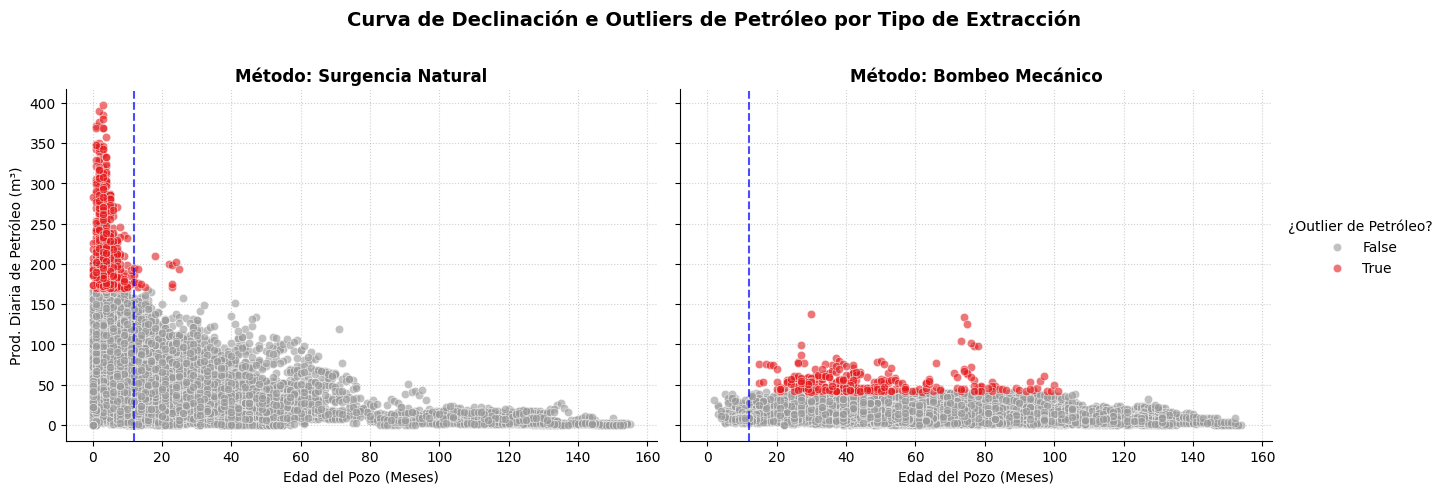

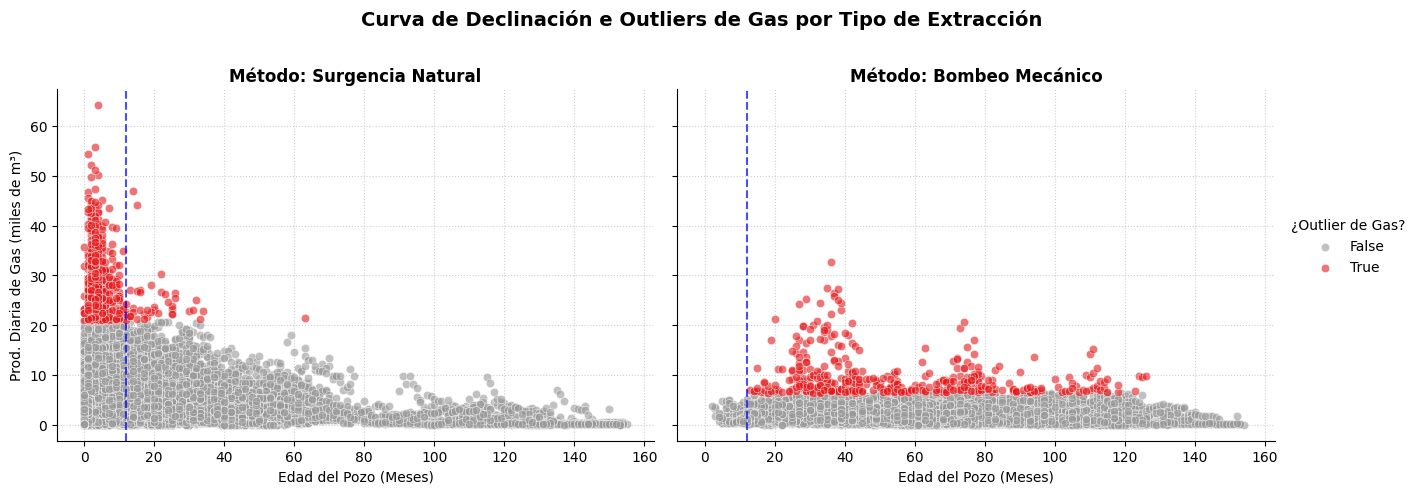

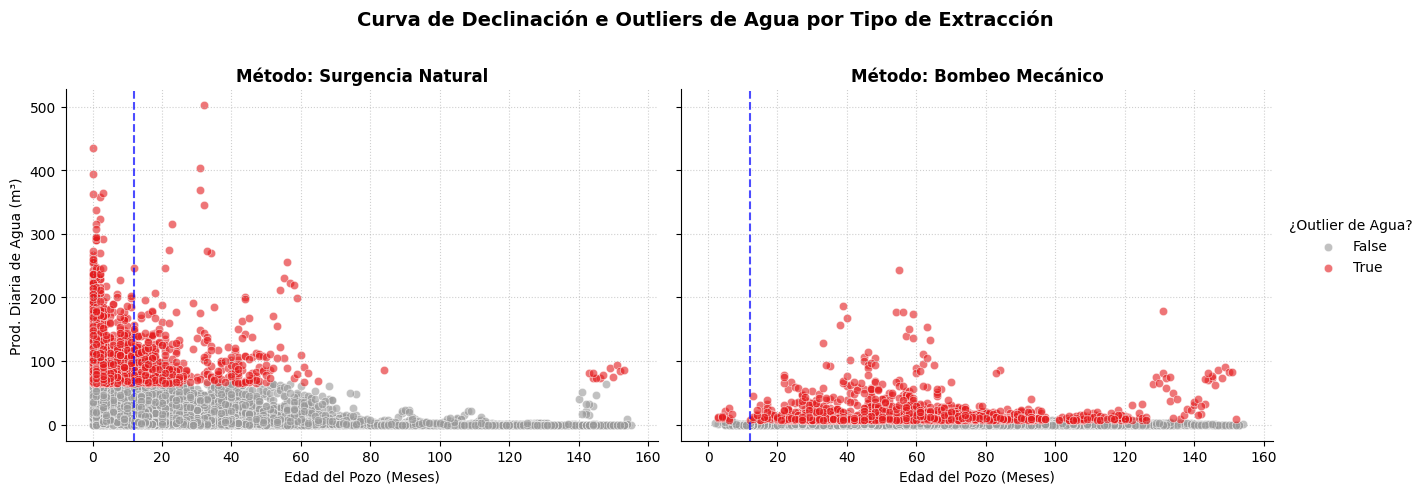

In [92]:
df_plot = df_plot[df_plot['tipopozo'] == 'Petrolífero'].copy()

# 1. Identificar outliers por grupo usando el método IQR para cada fluido de manera independiente
fluidos = {
    'Petróleo': {'col_prod': 'prod_pet_dia', 'col_outlier': 'es_outlier_petroleo', 'unidad': 'm³'},
    'Gas': {'col_prod': 'prod_gas_dia', 'col_outlier': 'es_outlier_gas', 'unidad': 'miles de m³'},
    'Agua': {'col_prod': 'prod_agua_dia', 'col_outlier': 'es_outlier_agua', 'unidad': 'm³'}
}

for fluido, info in fluidos.items():
    col = info['col_prod']
    grupos = df_plot.groupby(['tipopozo', 'tipoextraccion'])[col]
    Q1 = grupos.transform('quantile', 0.25)
    Q3 = grupos.transform('quantile', 0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    df_plot[info['col_outlier']] = df_plot[col] > limite_superior

# 2. Visualizaciones individuales por cada tipo de fluido
for fluido, info in fluidos.items():
    g = sns.FacetGrid(
        data=df_plot,
        col='tipoextraccion',
        hue=info['col_outlier'],
        palette={True: '#e41a1c', False: '#999999'},
        height=5,
        aspect=1.3,
        hue_order=[False, True]
    )

    g.map_dataframe(
        sns.scatterplot,
        x='edad_pozo_meses',
        y=info['col_prod'],
        alpha=0.6
    )

    # Personalizar cada subgráfico utilizando dinámicamente g.col_names
    for ax, title in zip(g.axes.flat, g.col_names):
        ax.set_title(f'Método: {title}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Edad del Pozo (Meses)', fontsize=10)
        ax.set_ylabel(f'Prod. Diaria de {fluido} ({info["unidad"]})', fontsize=10)
        ax.axvline(x=12, color='blue', linestyle='--', alpha=0.7, label='Primer año')
        ax.grid(True, linestyle=':', alpha=0.6)

    g.add_legend(title=f'¿Outlier de {fluido}?')
    g.figure.subplots_adjust(top=0.82)
    g.figure.suptitle(f'Curva de Declinación e Outliers de {fluido} por Tipo de Extracción', fontsize=14, fontweight='bold')

    plt.show()

Para los pozos petrolífero, con el método de surgencia natural, los outliers suceden antes del año del pozo, indicando que se tienen una buena eficiencia en los primeros meses que luego decae y por ello se cambia de método de extracción

In [93]:
produccion_anual = df_filtrado.groupby('anio')[['prod_pet', 'prod_gas', 'prod_agua']].sum(min_count=1)
cobertura_anual = df_filtrado.groupby('anio').agg(
    meses_observados=('mes', 'nunique'), registros=('idpozo', 'size'), pozos=('idpozo', 'nunique')
)
display(produccion_anual.join(cobertura_anual))

# Reconstruimos la fecha máxima a partir de 'anio' y 'mes' para evitar el KeyError
ultimo_anio = df_filtrado['anio'].max()
ultimo_mes = df_filtrado.loc[df_filtrado['anio'] == ultimo_anio, 'mes'].max()
print(f'Último mes observado: {ultimo_anio}-{ultimo_mes:02d}')

,prod_pet,prod_gas,prod_agua,meses_observados,registros,pozos
anio,,,,,,
2013,13727.00,1259.92,13544.65,3,27,15
2014,73082.32,10461.35,31502.36,12,228,19
2015,252003.69,98472.62,130186.03,12,406,49
2016,651651.79,486819.21,313241.03,12,988,106
2017,641816.26,1205010.33,433923.54,12,1487,137
2018,588330.71,1816494.84,381350.94,12,1694,155
2019,1078119.97,1435647.78,332249.24,12,1967,180
2020,1490275.11,738083.78,406206.19,12,2057,196
2021,2357324.95,1143889.26,654091.59,12,2158,212


Último mes observado: 2026-09


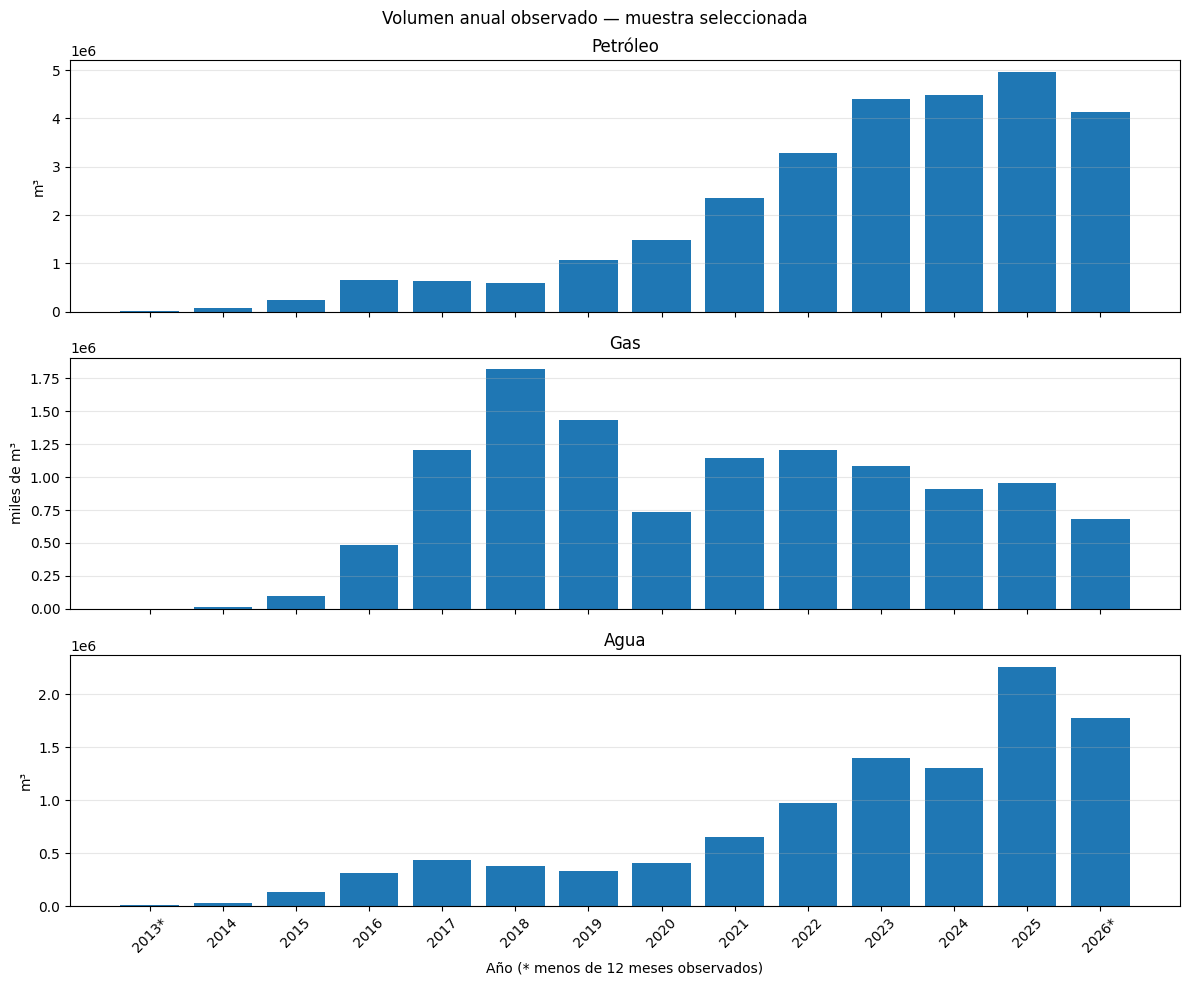

Comparación de enero a mes 9; revisar también cobertura y cantidad de pozos.


,prod_pet,prod_gas,prod_agua
anio,,,
2014,59437.97,8578.82,30321.69
2015,153887.13,48952.35,91016.66
2016,484478.36,297637.77,206365.71
2017,508023.35,843117.33,323629.90
2018,391721.28,1352980.53,282597.69
2019,720464.16,1159748.83,221343.77
2020,1088504.28,577418.51,299066.71
2021,1693758.47,837736.10,483708.56
2022,2280739.35,912930.16,644290.98


In [94]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, col, nombre, unidad in zip(axes,
        ['prod_pet', 'prod_gas', 'prod_agua'],
        ['Petróleo', 'Gas', 'Agua'], ['m³', 'miles de m³', 'm³']):
    etiquetas = [f"{anio}*" if cobertura_anual.loc[anio, 'meses_observados'] < 12 else str(anio)
                 for anio in produccion_anual.index]
    ax.bar(etiquetas, produccion_anual[col])
    ax.set_title(nombre)
    ax.set_ylabel(unidad)
    ax.grid(axis='y', alpha=0.3)
axes[-1].set_xlabel('Año (* menos de 12 meses observados)')
axes[-1].tick_params(axis='x', rotation=45)
fig.suptitle('Volumen anual observado — muestra seleccionada')
plt.tight_layout()
plt.show()
# Comparación al mismo mes de corte para todos los años.
mes_corte = int(df_filtrado.loc[df_filtrado['anio'].eq(df_filtrado['anio'].max()), 'mes'].max())
print(f'Comparación de enero a mes {mes_corte}; revisar también cobertura y cantidad de pozos.')
display(df_filtrado.loc[df_filtrado['mes'].le(mes_corte)].groupby('anio')[['prod_pet', 'prod_gas', 'prod_agua']].sum(min_count=1))

,meses_observados
count,512.000000
mean,53.376953
std,33.851010
min,1.000000
25%,26.000000
50%,46.500000
75%,79.250000
max,139.000000


Cantidad de pozos con correlación válida por par:


,prod_agua,prod_gas,prod_pet,tef
prod_agua,465,465,440,465
prod_gas,465,466,441,466
prod_pet,440,441,441,441
tef,465,466,441,466


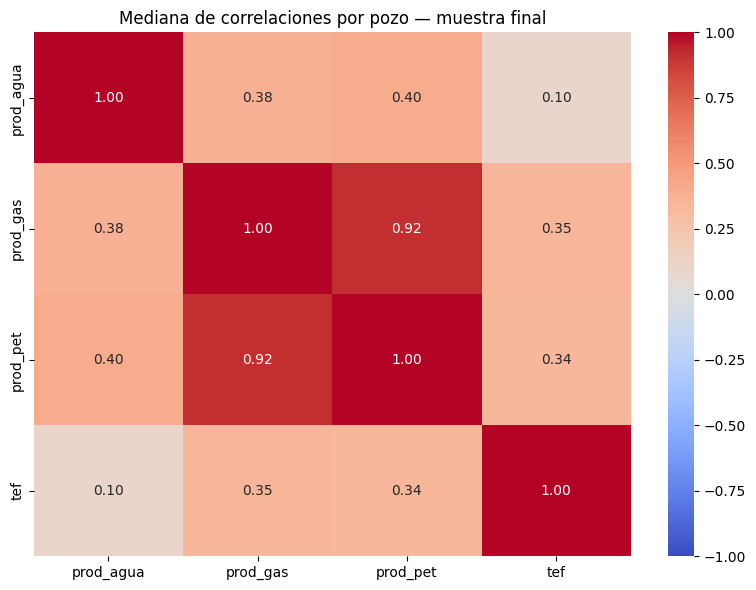

In [95]:
cols = ['prod_agua', 'prod_gas', 'prod_pet', 'tef']
base_corr = df_filtrado.loc[df_filtrado['tipoestado'].eq('Extracción Efectiva')].copy()
MIN_OBSERVACIONES = 12  # Umbral operativo explícito; no garantiza estabilidad estadística.
resumen_pozo = base_corr.groupby('idpozo').size().rename('meses_observados')
display(resumen_pozo.describe())
pozos_corr = resumen_pozo[resumen_pozo >= MIN_OBSERVACIONES].index
corr_por_pozo = base_corr.loc[base_corr['idpozo'].isin(pozos_corr)].groupby('idpozo')[cols].corr(min_periods=MIN_OBSERVACIONES)
matriz_corr = corr_por_pozo.groupby(level=1).median().reindex(index=cols, columns=cols)
aportes = corr_por_pozo.groupby(level=1).count().reindex(index=cols, columns=cols)
print('Cantidad de pozos con correlación válida por par:')
display(aportes)
if matriz_corr.notna().any().any():
    plt.figure(figsize=(8, 6))
    sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
    plt.title('Mediana de correlaciones por pozo — muestra final')
    plt.tight_layout()
    plt.show()
else:
    print('No hay suficientes pares válidos para graficar correlaciones.')

La correlación es alta entre prod_pet y prod_gas, media entre tef y prod_gas, tef y prod_pet, prod_agua y prod_pet, prod_agua y prod_gas

In [96]:
from google.colab import files

# Guardar el dataset limpio y filtrado, sin el índice de pandas
nombre_archivo = 'produccion_limpia_filtrada.csv'

df_filtrado.to_csv(
    nombre_archivo,
    index=False,
    encoding='utf-8-sig'
)

# Descargarlo a tu computadora
files.download(nombre_archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusión


El dataset filtrado son datos de la empresa YPF, de tres áreas:

*   Loma Campana
*   La Amarga Chica
*   El Orejano

La formación a interes es vaca muerta y los métodos de extracción seleccionados fueron los pozos que utilizaron exactamente:

*   Bombeo Mecánico y Surgencia Natural
*   Surgencia Natural

Los hallazgos demuestran que la surgencia natural se utiliza en los primeros meses de actividad del pozo, con una mejora en su extracción y que luego se decide cambiar de método de extracción a, por ejemplo, bombeo mecánico.

Hay una buena correlación entre las variables de producción por lo que para los modelos de predicción de producción será interesante predecir las tres en conjunto.